EXPERIMENT - 3


In [51]:
pip install "numpy<2.0" gym gym_bandits

In [52]:
import gym
import gym_bandits
import numpy as np

In [53]:
env = gym.make('MultiarmedBandits-v0')

In [54]:
print(env.observation_space)

Discrete(1)


In [55]:
print(env.action_space)

Discrete(10)


In [56]:
import warnings
n_arms = env.action_space.n
num_episodes = 500

epsilon = 0.1

q_values = np.zeros(n_arms)
counts = np.zeros(n_arms)
reward_sums = np.zeros(n_arms)

all_rewards = []
action_history = []

warnings.filterwarnings('ignore', category=DeprecationWarning)

In [58]:
for episode in range(num_episodes):
  env.reset()

  if np.random.rand() < epsilon:
    action = env.action_space.sample()
  else:
    action = np.argmax(q_values)

  observation, reward, done, info = env.step(action)

  counts[action] += 1
  reward_sums[action] += reward
  q_values[action] = reward_sums[action] / counts[action]
  all_rewards.append(reward[0]) # Add this line to record the reward
env.close()

print("Estimating Q-values for each arm: ", np.round(q_values, 2))
print("Number of times each arm was Selected: ", counts.astype(int))
print("Average reward over all episodes: ", round(np.mean(all_rewards), 3))

Estimating Q-values for each arm:  [-0.05  0.   -0.19 -0.64 -0.65 -0.04 -0.13 -0.    0.08 -0.23]
Number of times each arm was Selected:  [ 17  50   8   7   7   7  26 195 176   7]
Average reward over all episodes:  -0.007


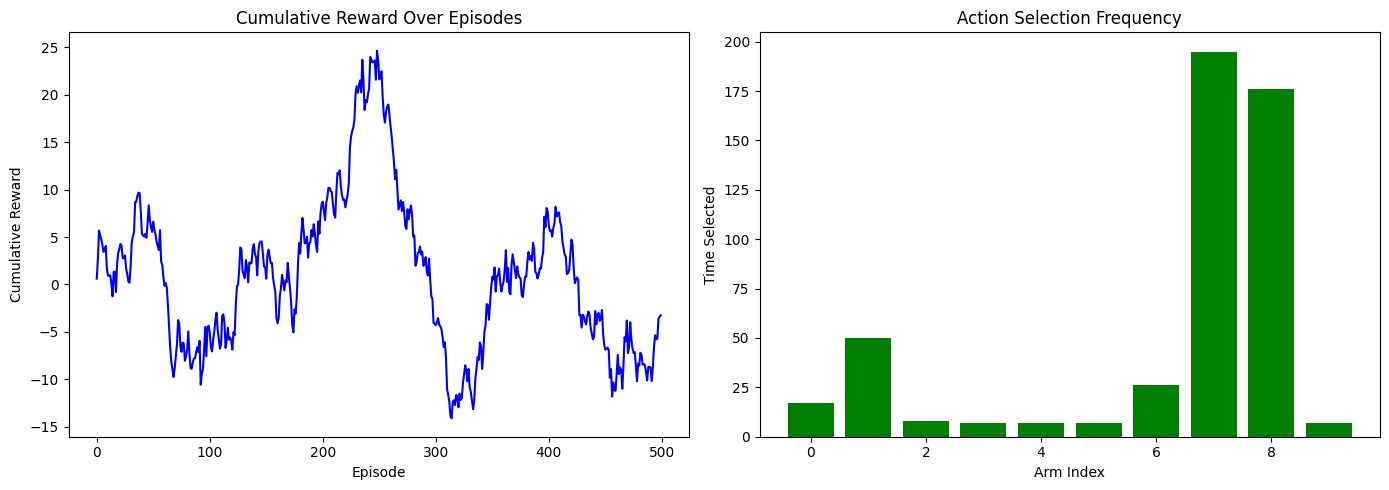

In [59]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,5))

plt.subplot(1,2,1)
plt.plot(np.cumsum(all_rewards), color='blue')
plt.title("Cumulative Reward Over Episodes")
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")

plt.subplot(1,2,2)
plt.bar(np.arange(n_arms), counts, color='green')
plt.title("Action Selection Frequency")
plt.xlabel("Arm Index")
plt.ylabel("Time Selected")

plt.tight_layout()
plt.show()